<center>
    <p style="color: red; font-size: 20px;">Tên: Lê Thiên Hạo</p>
</center>
<center>
    <p style="color: red; font-size: 20px;">MSSV: 089206010393</p>
</center>

# 1. Nạp dự liệu iris vào bộ nhớ và hiển thị thông tin về số thuộc tính (dimensionality), số objects (size).

In [1]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame= True)

In [2]:
iris

{'data':      sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
 0                  5.1               3.5                1.4               0.2
 1                  4.9               3.0                1.4               0.2
 2                  4.7               3.2                1.3               0.2
 3                  4.6               3.1                1.5               0.2
 4                  5.0               3.6                1.4               0.2
 ..                 ...               ...                ...               ...
 145                6.7               3.0                5.2               2.3
 146                6.3               2.5                5.0               1.9
 147                6.5               3.0                5.2               2.0
 148                6.2               3.4                5.4               2.3
 149                5.9               3.0                5.1               1.8
 
 [150 rows x 4 columns],
 'target': 0     

In [3]:
iris.data.head(20)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
5,5.4,3.9,1.7,0.4
6,4.6,3.4,1.4,0.3
7,5.0,3.4,1.5,0.2
8,4.4,2.9,1.4,0.2
9,4.9,3.1,1.5,0.1


## Hiển thị thông tin của thuộc tính

In [4]:
iris.data.shape

(150, 4)

In [5]:
iris.data.columns

Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)'],
      dtype='object')

# 2. Đặt nhãn (label) cho dữ liệu đã nạp và hiển thị số lớp (classes)

In [6]:
labels = ['setosa', 'versicolor', 'virginica']

In [7]:
iris.target = iris.target.apply(lambda x: labels[x])

In [8]:
iris.target

0         setosa
1         setosa
2         setosa
3         setosa
4         setosa
         ...    
145    virginica
146    virginica
147    virginica
148    virginica
149    virginica
Name: target, Length: 150, dtype: object

# 3. Tách dữ liệu thành hai phần: training data(70%) và test data (30%)

In [9]:
from sklearn.model_selection import train_test_split
train_x , test_x, train_y, test_y  = train_test_split(iris.data, iris.target, test_size= 0.3)

# 4. Chuẩn hóa dữ liệu với StandardScaler

In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
fitted_train_x = scaler.fit_transform(train_x)
fitted_test_x = scaler.fit_transform(test_x)

# 5. Tạo và huấn luyện mô hình với training data

In [11]:
from sklearn.tree import DecisionTreeClassifier

tree_clf = DecisionTreeClassifier(max_depth=2) 
tree_clf.fit(fitted_train_x, train_y)

,criterion,'gini'
,splitter,'best'
,max_depth,2
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [12]:
from sklearn.tree import export_graphviz
export_graphviz(
    tree_clf,
    out_file="iris.dot",
    feature_names=train_x.columns,
    class_names=labels,
    rounded=True,
    filled=True
)

In [13]:
!dot -Tpng iris.dot -o iris.png

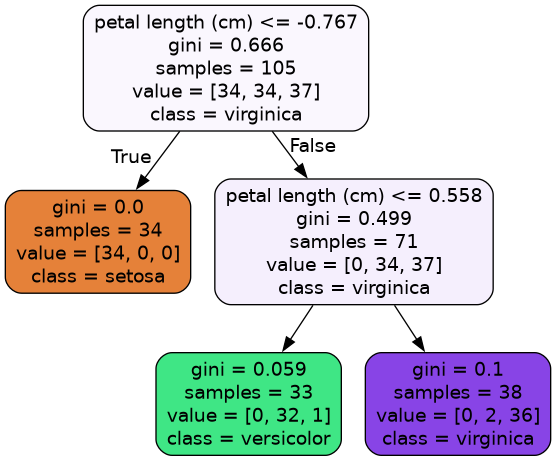

# 6. Test và đánh giá độ chính xác của mô mình, yêu cầu hiển thị ma trận confusion matrix, accuracy, f-score

In [14]:
pred = tree_clf.predict(fitted_test_x)

In [15]:
from sklearn.metrics import accuracy_score, precision_score, f1_score, classification_report, confusion_matrix

In [16]:
print(classification_report(test_y, pred))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        17
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.89      0.94        18

    accuracy                           0.96        45
   macro avg       0.94      0.96      0.95        45
weighted avg       0.96      0.96      0.96        45



In [17]:
confusion_matrix(test_y,pred)

array([[17,  0,  0],
       [ 0, 10,  0],
       [ 0,  2, 16]])

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt

Confusion matrix, without normalization
[[17  0  0]
 [ 0 10  0]
 [ 0  2 16]]
Normalized confusion matrix
[[1.   0.   0.  ]
 [0.   1.   0.  ]
 [0.   0.11 0.89]]


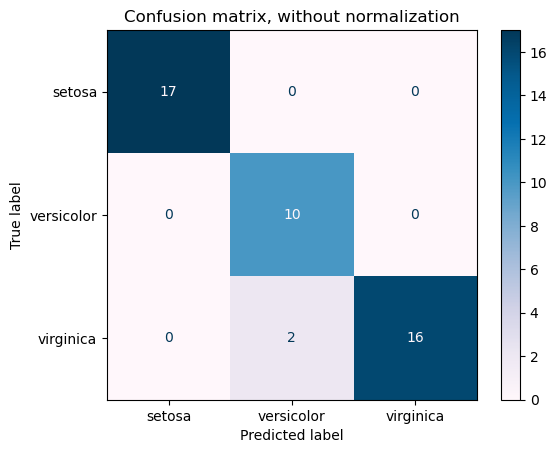

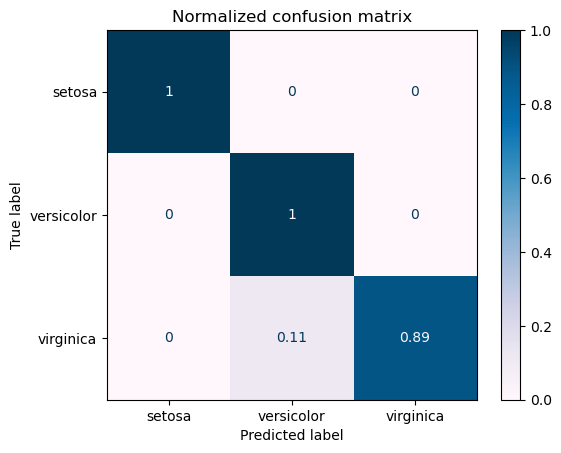

In [19]:
np.set_printoptions(precision=2)

titles_options = [
    ("Confusion matrix, without normalization", None),
    ("Normalized confusion matrix", "true"),
]
for title, normalize in titles_options:
    disp = ConfusionMatrixDisplay.from_estimator(
        tree_clf,
        fitted_test_x,
        test_y,
        display_labels=labels,
        cmap=plt.cm.PuBu,
        normalize=normalize,
    )
    disp.ax_.set_title(title)

    print(title)
    print(disp.confusion_matrix)

plt.show()


# 2.3 Thử điều chỉnh các tham số của cây quyết định và chọn tham số cho kết quả là giá trị f-score tốt nhất

- Thử nhiều tham số cho mô hình test từng các thông số thông qua `GridSearchCV`

In [30]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

params = {
    'max_depth': [2, 3, 4, 5, 6, None],
    'min_samples_split': [2, 3, 4, 5, 10],
    'min_samples_leaf': [1, 2, 3, 4, 5],
    'criterion': ['gini', 'entropy'],
}

grid = GridSearchCV(DecisionTreeClassifier(random_state=42), params, cv=5, scoring='f1_macro', n_jobs=-1)
grid.fit(fitted_train_x, train_y)
print(grid.best_params_)
best_tree = grid.best_estimator_

{'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}


### Kết quả:
- sử thang đo `gini`
- độ xâu của cây là `5`
- số lá it nhất là `1`

In [31]:
best_pred = best_tree.predict(fitted_test_x)

In [32]:
print(classification_report(test_y, pred))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        17
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.89      0.94        18

    accuracy                           0.96        45
   macro avg       0.94      0.96      0.95        45
weighted avg       0.96      0.96      0.96        45

